# 03 · Los privados urbanos grandes de Australia

En `03_regresion_por_edicion`, la pendiente de los recursos de estudio del privado urbano grande (`PRI_URB_MACRO`) salta de 3,39 puntos por desviación típica en 2012 a 17,65 en 2022, y es lo único que hace distintas las pendientes de los perfiles en 2022. `03_robustez_regresion` (sección 4) muestra que el salto desaparece al quitar Australia, que aporta la mayoría de los centros de ese perfil. Este notebook mira qué pasa allí:

* ¿Es un cambio de toda Australia o de sus privados grandes? (sección 1)
* ¿Quiénes son, en esos centros, los alumnos sin todos los recursos, y cuánto peor les va? (sección 2)
* ¿Viene de un recurso concreto? (sección 3)
* ¿Es una diferencia entre centros o dentro de cada centro? (sección 4)
* ¿Pasa solo en matemáticas? (sección 5)
* ¿Influyen los alumnos sin dato de recursos? (sección 6)

Las regresiones son las de `src/modelo_regresion.py` (`SENWT`, errores agrupados por centro, valores plausibles con Rubin), con solo los alumnos de Australia (sin efecto fijo de país, que es uno solo). Las medias de nota usan la media de los valores plausibles de cada alumno, ponderada con `SENWT`.

## 0. Configuración

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.modelo_regresion import coeficientes_con_error, estimar_por_edicion
from src.pisa_estadisticas import media_ponderada
from src.preparacion_modelo import CONTROLES, MINIMO_CENTROS, matriz_regresion

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)

EDICIONES = [2012, 2015, 2018, 2022]
PAIS, PERFIL = 'AUS', 'PRI_URB_MACRO'
RUTA_PROCESADOS = '../../data/processed'
RUTA_INTERMEDIOS = '../../data/intermediate'
RUTA_REPORTS = '../../reports'
ITEMS = ['habitacion_propia', 'ordenador_estudios', 'internet', 'libros_ayuda_estudios', 'libros_tecnicos', 'diccionario']
TRAMOS = ['faltan dos o más', 'falta uno', 'los seis']
COLORES_TRAMO = dict(zip(TRAMOS, plt.cm.Blues([0.45, 0.7, 0.95])))
GRUPOS = [PERFIL, 'resto de Australia']

tabla = pd.read_parquet(os.path.join(RUTA_PROCESADOS, 'tabla_modelo_alumno.parquet'))
parametros = pd.read_parquet(os.path.join(RUTA_PROCESADOS, 'parametros_escala.parquet'))
matriz = matriz_regresion(tabla, parametros)
matriz_pais = matriz[matriz['CNT'] == PAIS]

# Los seis recursos uno a uno, para los alumnos de Australia
items = pd.read_parquet(os.path.join(RUTA_INTERMEDIOS, 'recursos_alumno_anual', 'pisa_recursos_alumno_anual.parquet'),
                        columns=['CNT', 'CNTSCHID', 'CNTSTUID', 'year'] + ITEMS)
items[['CNT', 'CNTSCHID', 'CNTSTUID']] = items[['CNT', 'CNTSCHID', 'CNTSTUID']].astype(str)
alumnos_pais = tabla[tabla['CNT'] == PAIS].merge(items, on=['CNT', 'CNTSCHID', 'CNTSTUID', 'year'], how='left', validate='one_to_one')
# Nota media de los valores plausibles, grupo (el perfil frente al resto del país) y tramo de recursos
alumnos_pais['nota'] = alumnos_pais.filter(regex=r'^PV\d+MATH$').mean(axis=1)
alumnos_pais['grupo'] = np.where(alumnos_pais['perfil'] == PERFIL, PERFIL, 'resto de Australia')
alumnos_pais['tramo'] = np.select([alumnos_pais['recursos_estudio'] >= 6, alumnos_pais['recursos_estudio'] >= 4.5], TRAMOS[:0:-1], TRAMOS[0])
alumnos_pais.loc[alumnos_pais['recursos_estudio'].isna(), 'tramo'] = 'sin dato'


print(f'{len(matriz_pais)} alumnos de {PAIS} en el modelo; de ellos, en {PERFIL}:', matriz_pais[matriz_pais['perfil'] == PERFIL].groupby('year').size().to_dict())

36219 alumnos de AUS en el modelo; de ellos, en PRI_URB_MACRO: {2012: 782, 2015: 1147, 2018: 1023, 2022: 1495}


## 1. ¿Toda Australia o sus privados grandes?

La pendiente común de los recursos de estudio en Australia y en los otros 11 países, y la de cada perfil dentro de Australia. Si la pendiente sube en 2022 en toda Australia, el privado grande solo sería la parte más visible; si sube solo en él, es algo de esos centros. En la tabla por perfil, `*` marca los perfiles con menos de 30 centros de Australia en esa edición, con pendientes muy poco precisas.

**Pendiente común de los recursos de estudio (error típico), puntos por desviación típica**

year,2012,2015,2018,2022
AUS,3.3 (1.2),3.8 (1.4),2.4 (1.3),7.9 (1.0)
otros 11 países,5.5 (0.6),5.7 (0.6),5.1 (0.6),5.5 (0.5)


**Pendiente de los recursos de estudio por perfil dentro de AUS (error típico)**; `*` = menos de 30 centros de AUS

year,2012,2015,2018,2022
CON_RUR_MACRO,41.6 (9.9)*,6.4 (6.9)*,17.5 (16.3)*,20.9 (10.7)*
CON_RUR_MED,5.8 (16.9)*,-2.8 (5.8)*,-6.2 (6.8)*,10.6 (7.0)*
CON_RUR_PEQ,23.7 (10.3)*,-10.4 (13.0)*,-7.4 (13.4)*,12.4 (16.6)*
CON_URB_MACRO,-3.1 (3.0),-0.8 (2.8),1.2 (2.8),5.1 (2.4)
CON_URB_MED,2.3 (3.4),8.3 (3.9),2.6 (4.3),6.4 (4.6)
CON_URB_PEQ,0.7 (11.6)*,-6.9 (14.0)*,16.0 (12.4)*,11.4 (5.1)*
PRI_URB_MACRO,0.0 (4.7),2.9 (3.3),-4.8 (4.1),19.4 (3.2)
PRI_URB_MED,8.3 (11.1)*,-1.6 (7.6)*,7.7 (5.7)*,9.1 (6.9)*
PRI_URB_PEQ,7.0 (12.3)*,-11.7 (7.2)*,4.5 (14.4)*,-27.0 (12.6)*
PUB_RUR_MACRO,-1.2 (5.8)*,10.6 (4.2)*,4.2 (5.2)*,6.2 (7.0)*


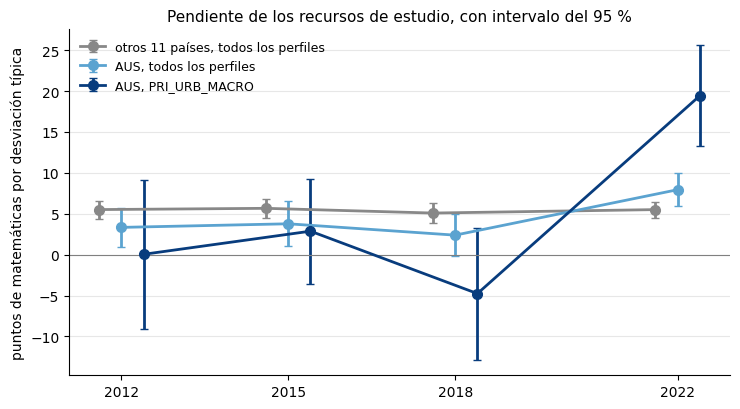

In [2]:
# Pendiente común en Australia y en los otros 11 países, y pendiente por perfil dentro de Australia
comun_pais, _ = estimar_por_edicion(matriz_pais, False)
comun_resto, _ = estimar_por_edicion(matriz[matriz['CNT'] != PAIS], False)
perfil_pais, _ = estimar_por_edicion(matriz_pais, True)
comparacion = pd.concat({PAIS: coeficientes_con_error(comun_pais, ['recursos_estudio']), 'otros 11 países': coeficientes_con_error(comun_resto, ['recursos_estudio'])}).droplevel('termino')
display(Markdown('**Pendiente común de los recursos de estudio (error típico), puntos por desviación típica**'))
display(comparacion)

# Tabla por perfil, marcando los que tienen menos de 30 centros australianos
terminos = sorted(termino for termino in perfil_pais.index.get_level_values('termino').unique() if termino.startswith('recursos_estudio:'))
centros_pais = matriz_pais.groupby(['perfil', 'year'])['centro'].nunique().unstack('year').fillna(0)
marcas = (centros_pais < MINIMO_CENTROS).replace({True: '*', False: ''})
por_perfil = coeficientes_con_error(perfil_pais, terminos)
por_perfil.index = [termino.split(':')[1] for termino in por_perfil.index]
display(Markdown(f'**Pendiente de los recursos de estudio por perfil dentro de {PAIS} (error típico)**; `*` = menos de 30 centros de {PAIS}'))
display(por_perfil + marcas.loc[por_perfil.index])

# Figura: pendiente de los recursos en los tres grupos
fig, eje = plt.subplots(figsize=(7.5, 4.2))
series = [('otros 11 países, todos los perfiles', comun_resto, 'recursos_estudio', plt.cm.Greys(0.55)),
          (f'{PAIS}, todos los perfiles', comun_pais, 'recursos_estudio', plt.cm.Blues(0.55)),
          (f'{PAIS}, {PERFIL}', perfil_pais, f'recursos_estudio:{PERFIL}', plt.cm.Blues(0.95))]
for desplazamiento, (etiqueta, tabla_estimada, termino, color) in zip((-0.4, 0, 0.4), series):
    fila = tabla_estimada.xs(termino, level='termino')
    eje.errorbar(np.array(EDICIONES) + desplazamiento, fila['coeficiente'], yerr=1.96 * fila['error_tipico'], color=color, marker='o', markersize=7,
                 linewidth=2, capsize=3, label=etiqueta)
eje.axhline(0, color='grey', linewidth=0.8)
eje.set_xticks(EDICIONES)
eje.set_ylabel('puntos de matemáticas por desviación típica')
eje.grid(axis='y', alpha=0.3)
eje.spines[['top', 'right']].set_visible(False)
eje.legend(fontsize=9, loc='upper left', frameon=False)
eje.set_title('Pendiente de los recursos de estudio, con intervalo del 95 %', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/03_australia_pendientes.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **En toda Australia la pendiente de los recursos sube en 2022**, aunque menos que en sus privados grandes: de 2,4-3,8 puntos por desviación típica en 2012-2018 pasa a 7,9 en 2022. En los otros 11 países se queda en 5,1-5,7 en todas las ediciones.
* **Dentro de Australia, el privado urbano grande es donde más sube**: de 0,0 en 2012 y −4,8 en 2018 a 19,4 en 2022 (error típico 3,2).
* **Los demás perfiles australianos con 30 centros o más suben poco en comparación.** El público urbano mediano llega a 9,7, el público urbano grande a 7,5 y el concertado urbano grande a 5,1.
* **El cambio es, por tanto, de dos niveles**: una subida general en Australia y una mucho mayor en sus privados grandes.

## 2. Los alumnos sin todos los recursos

Para los alumnos del modelo de Australia, la nota media de matemáticas por tramo de recursos de estudio («faltan dos o más», «falta uno», «los seis», como en `03_robustez_regresion`, sección 3), en el privado urbano grande y en el resto de Australia. Junto a la nota, el número de alumnos, la ocupación de los padres (`HISEI_TREND`), la composición social de su centro y el porcentaje de inmigrantes, para ver si los alumnos sin recursos de 2022 son distintos de los de antes.

**PRI_URB_MACRO**

alumnos                                nota                               HISEI                    composicion_centro                        % inmigrante                   
tramo faltan dos o más falta uno los seis faltan dos o más falta uno los seis faltan dos o más falta uno los seis   faltan dos o más falta uno los seis faltan dos o más falta uno los seis
year                                                                                                                                                                                       
2012              76.0     237.0    469.0            555.2     555.0    570.1             65.0      65.7     69.7                0.6       0.6      0.7             22.6      20.2     25.5
2015             137.0     338.0    672.0            514.9     545.2    551.2             58.0      66.7     70.7                0.6       0.6      0.6             27.2      21.8     29.8
2018             146.0     319.0    558.0            538.9     563.8    549.2             66.9      69.9     70.4                0.7       0.7      0.7             19.9      18.6     26.9
2022             150.0     328.0   1017.0            476.7     522.4    563.0             64.3      69.2     71.5                0.7       0.7      0.8             13.8      25.2     23.2

**resto de Australia**

alumnos                                nota                               HISEI                    composicion_centro                        % inmigrante                   
tramo faltan dos o más falta uno los seis faltan dos o más falta uno los seis faltan dos o más falta uno los seis   faltan dos o más falta uno los seis faltan dos o más falta uno los seis
year                                                                                                                                                                                       
2012            1901.0    2497.0   3219.0            474.8     501.1    520.3             49.7      54.9     59.4               -0.1      -0.0      0.1             21.3      22.1     24.0
2015            2593.0    2868.0   3717.0            464.7     499.1    509.9             49.6      55.8     59.7               -0.1       0.1      0.2             22.9      25.8     28.3
2018            2071.0    2203.0   2704.0            471.6     501.5    508.9             49.2      55.4     59.3               -0.0       0.1      0.2             24.7      31.2     31.7
2022            1620.0    2129.0   4250.0            453.3     489.6    511.8             51.6      57.6     62.5                0.2       0.3      0.4             27.6      36.4     31.3

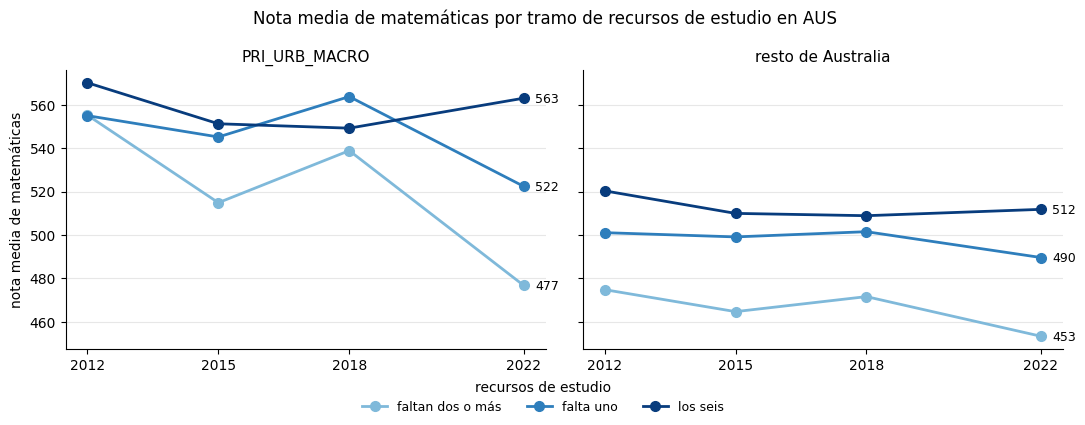

In [3]:
# Por grupo, edición y tramo: alumnos, nota y composición social (medias ponderadas)
en_modelo = alumnos_pais[alumnos_pais['en_modelo']]
perfil_tramo = en_modelo.groupby(['grupo', 'year', 'tramo']).apply(lambda grupo: pd.Series({
    'alumnos': len(grupo), 'nota': media_ponderada(grupo['nota'], grupo['SENWT']), 'HISEI': media_ponderada(grupo['HISEI_TREND'], grupo['SENWT']),
    'composicion_centro': media_ponderada(grupo['composicion_social_centro'], grupo['SENWT']),
    '% inmigrante': 100 * media_ponderada(grupo['inmigrante'], grupo['SENWT'])}), include_groups=False)
for grupo in GRUPOS:
    display(Markdown(f'**{grupo}**'))
    display(perfil_tramo.loc[grupo].unstack('tramo').reindex(columns=TRAMOS, level='tramo').round(1))

# Figura: nota media de cada tramo por edición
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for eje, grupo in zip(ejes, GRUPOS):
    for tramo in TRAMOS:
        serie = perfil_tramo.loc[grupo].xs(tramo, level='tramo')['nota']
        eje.plot(serie.index, serie.to_numpy(), marker='o', markersize=7, linewidth=2, color=COLORES_TRAMO[tramo], label=tramo)
        eje.annotate(f'{serie.iloc[-1]:.0f}', (serie.index[-1], serie.iloc[-1]), textcoords='offset points', xytext=(8, -3), fontsize=9)
    eje.set_title(grupo, fontsize=11)
    eje.set_xticks(EDICIONES)
    eje.grid(axis='y', alpha=0.3)
    eje.spines[['top', 'right']].set_visible(False)
ejes[0].set_ylabel('nota media de matemáticas')
fig.legend(*ejes[0].get_legend_handles_labels(), title='recursos de estudio', loc='lower center', ncol=3, fontsize=9, frameon=False)
fig.suptitle(f'Nota media de matemáticas por tramo de recursos de estudio en {PAIS}', fontsize=12)
plt.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(f'{RUTA_REPORTS}/03_australia_nota_por_tramo.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **En los privados grandes, en 2022 cae la nota de los alumnos a los que les faltan recursos.**
  * Los alumnos con los seis recursos sacan 563,0 en 2022, como en ediciones anteriores (570,1 en 2012).
  * Los que tienen dos o más recursos de menos pasan de 555,2 en 2012 a 476,7 en 2022.
  * Los que tienen uno de menos, de 555,0 a 522,4.
  * Hasta 2018, los tres grupos sacaban notas parecidas en estos centros.
* **En el resto de Australia la diferencia entre tramos siempre fue grande** (474,8 frente a 520,3 en 2012) y en 2022 se amplía algo menos (453,3 frente a 511,8).
* **No son alumnos de otro origen social.**
  * En los privados grandes, los alumnos con dos o más recursos de menos tienen en 2022 una ocupación de los padres parecida a la de 2012 (64,3 frente a 65,0).
  * Estudian en centros de composición social parecida.
  * Hay menos inmigrantes entre ellos (13,8 % frente a 22,6 %).
  * El cambio, por tanto, no está en quiénes son esos alumnos, sino en lo que les pasa.

## 3. ¿Un recurso concreto?

Para cada uno de los seis recursos, el porcentaje de alumnos del modelo que no lo tienen y, en el privado urbano grande, la nota media de los que lo tienen y de los que no. Si el salto viniera de un solo recurso (por ejemplo, uno cuya pregunta cambió en 2022), la diferencia de nota crecería solo en él.

In [4]:
# % de alumnos sin cada recurso
sin_item = en_modelo.groupby(['grupo', 'year']).apply(lambda grupo: pd.Series({item: 100 * (1 - media_ponderada(grupo[item], grupo['SENWT'])) for item in ITEMS}),
                                                    include_groups=False)
display(Markdown('**% de alumnos sin cada recurso**'))
display(sin_item.round(1))

# En el perfil, diferencia de nota entre quien tiene cada recurso y quien no
del_perfil = en_modelo[en_modelo['grupo'] == PERFIL]
filas = []
for item in ITEMS:
    for edicion, grupo in del_perfil.groupby('year'):
        sin, con = grupo[grupo[item] == 0], grupo[grupo[item] == 1]
        filas.append({'recurso': item, 'year': edicion, 'alumnos sin él': len(sin), 'nota sin él': media_ponderada(sin['nota'], sin['SENWT']),
                      'nota con él': media_ponderada(con['nota'], con['SENWT'])})
diferencias = pd.DataFrame(filas)
diferencias['diferencia'] = diferencias['nota con él'] - diferencias['nota sin él']
display(Markdown(f'**{PERFIL} de {PAIS}: diferencia de nota media entre los que tienen cada recurso y los que no**'))
display(diferencias.pivot(index='recurso', columns='year', values='diferencia').loc[ITEMS].round(1))
display(diferencias.pivot(index='recurso', columns='year', values='alumnos sin él').loc[ITEMS])

**% de alumnos sin cada recurso**

habitacion_propia  ordenador_estudios  internet  libros_ayuda_estudios  libros_tecnicos  diccionario
grupo              year                                                                                                      
PRI_URB_MACRO      2012                5.1                 0.1       0.6                    7.6             35.0          0.8
                   2015                5.2                 1.2       0.5                    9.7             36.8          2.9
                   2018                4.4                 1.0       0.1                    9.5             39.1          6.0
                   2022                3.1                 0.4       0.3                    5.0             29.8         11.6
resto de Australia 2012                7.8                 2.1       2.8                   20.3             49.9          4.0
                   2015                8.0                 5.1       3.4                   20.5             49.2          6.8
                   2018                7.2                 5.9       2.1                   23.0             52.4         13.7
                   2022                7.4                 3.0       1.3                   13.7             38.8         18.3

**PRI_URB_MACRO de AUS: diferencia de nota media entre los que tienen cada recurso y los que no**

year,2012,2015,2018,2022
recurso,,,,
habitacion_propia,-18.9,44.3,5.5,14.5
ordenador_estudios,75.8,64.0,56.4,69.8
internet,54.7,73.7,41.6,86.4
libros_ayuda_estudios,11.7,25.3,10.4,60.7
libros_tecnicos,20.4,12.0,-4.3,59.9
diccionario,41.0,35.5,-1.6,58.2


year,2012,2015,2018,2022
recurso,,,,
habitacion_propia,39,70,47,48
ordenador_estudios,4,19,8,6
internet,9,16,2,6
libros_ayuda_estudios,69,115,107,81
libros_tecnicos,276,405,410,350
diccionario,12,36,62,177


**Qué se ve.**

* **El salto no viene de un recurso concreto.** En los privados grandes, la diferencia de nota entre tener y no tener crece en 2022 en casi todos los recursos:
  * libros de ayuda: de 11,7 puntos en 2012 a 60,7 en 2022;
  * libros técnicos: de 20,4 a 59,9;
  * diccionario: de 41,0 a 58,2;
  * internet: de 54,7 a 86,4.
  * El ordenador y el internet eran ya diferencias grandes y afectan a muy pocos alumnos (6 sin cada uno en 2022).
* **El diccionario cambia de significado.** Los alumnos sin diccionario pasan del 0,8 % en 2012 al 11,6 % en 2022 en los privados grandes, y del 4,0 % al 18,3 % en el resto de Australia. Seguramente se debe a los diccionarios digitales. Aun así, la diferencia de nota crece igual en los recursos cuya posesión no cambia tanto, así que no explica el salto.

## 4. ¿Entre centros o dentro de cada centro?

Si los alumnos sin recursos se concentraran en unos pocos privados grandes con peores resultados, la pendiente reflejaría diferencias entre centros. Se cuenta en cuántos centros hay alumnos con dos o más recursos de menos, y se estima la pendiente solo con los alumnos del privado urbano grande de Australia, primero sin y después con un indicador por centro (efecto fijo de centro). Con el efecto fijo, la pendiente compara solo alumnos del mismo centro; los controles del centro (composición social y dotación) salen, porque el indicador ya los absorbe.

In [5]:
# ¿Los alumnos con menos recursos se concentran en pocos centros?
del_perfil_2022 = del_perfil[del_perfil['year'] == 2022]
por_centro = del_perfil_2022.groupby('centro')['tramo'].apply(lambda tramos: (tramos == TRAMOS[0]).sum())
alumnos_centro = del_perfil_2022.groupby('centro').size()
print(f'{PERFIL} de {PAIS} en 2022: {len(por_centro)} centros; con algún alumno en «{TRAMOS[0]}»: {(por_centro > 0).sum()}; '
      f'máximo en un centro: {por_centro.max()} de sus {alumnos_centro[por_centro.idxmax()]} alumnos')

# Pendientes del perfil sin y con efecto fijo de centro (relación dentro de cada centro)
matriz_perfil = matriz_pais[matriz_pais['perfil'] == PERFIL]
sin_efecto_centro, _ = estimar_por_edicion(matriz_perfil, True)
# Los controles del centro no varían dentro de un centro: se quitan
controles_alumno = [variable for variable in CONTROLES if variable not in ('composicion_social_centro', 'dotacion_centro')]
# Cada centro hace de «país» en `matriz_diseno`, que crea un indicador por cada uno
con_efecto_centro, _ = estimar_por_edicion(matriz_perfil.assign(CNT=matriz_perfil['centro']), True, controles=controles_alumno)
terminos = [f'Indice_Compromiso_Competencia:{PERFIL}', f'recursos_estudio:{PERFIL}']
display(Markdown(f'**Pendientes en {PERFIL} de {PAIS} (error típico)**'))
display(pd.concat({'sin efecto fijo de centro': coeficientes_con_error(sin_efecto_centro, terminos), 'con efecto fijo de centro': coeficientes_con_error(con_efecto_centro, terminos)}))

PRI_URB_MACRO de AUS en 2022: 80 centros; con algún alumno en «faltan dos o más»: 67; máximo en un centro: 9 de sus 18 alumnos


**Pendientes en PRI_URB_MACRO de AUS (error típico)**

year                                                                         2012        2015        2018        2022
                          termino                                                                                    
sin efecto fijo de centro Indice_Compromiso_Competencia:PRI_URB_MACRO  10.5 (3.8)   9.8 (3.2)  10.9 (3.2)  12.4 (2.6)
                          recursos_estudio:PRI_URB_MACRO               -1.3 (4.9)   1.5 (3.5)  -6.0 (4.2)  17.9 (3.3)
con efecto fijo de centro Indice_Compromiso_Competencia:PRI_URB_MACRO  11.9 (3.8)   9.6 (3.2)  11.7 (3.1)  11.6 (2.7)
                          recursos_estudio:PRI_URB_MACRO               -2.5 (5.1)  -0.0 (3.5)  -6.4 (4.2)  15.6 (3.5)

**Qué se ve.**

* **Los alumnos sin recursos están repartidos por casi todos los centros**: en 67 de los 80 privados grandes de 2022 hay alguno con dos o más recursos de menos, y como mucho 9 en un centro.
* **El salto se ve igual dentro de cada centro.** Con efecto fijo de centro, la pendiente de los recursos pasa de −2,5 en 2012 y −6,4 en 2018 a 15,6 en 2022 (sin él, 17,9). No se debe a que los alumnos sin recursos estén en centros peores: en 2022, dentro de un mismo privado grande, al alumno al que le faltan recursos le va peor.
* **El compromiso no cambia** (de 11,9 a 11,6 con efecto fijo de centro). El cambio es solo de los recursos.

## 5. ¿Solo en matemáticas?

Si el salto es un rasgo de los alumnos (por ejemplo, que a los que les faltan recursos en casa les vaya peor en todo), debe verse también en lectura y en ciencias. Se repite el modelo de `03_regresion_por_edicion` (los 12 países, pendiente por perfil) y el de Australia sola, con la nota de cada asignatura.

In [6]:
# La pendiente de los recursos del perfil en las tres asignaturas, en los 12 países y en Australia
filas = []
for dominio in ['MATH', 'READ', 'SCIE']:
    for muestra, datos in (('12 países', matriz), (PAIS, matriz_pais)):
        estimada, _ = estimar_por_edicion(datos, True, dominio=dominio)
        fila = coeficientes_con_error(estimada, [f'recursos_estudio:{PERFIL}']).iloc[0]
        filas.append(fila.rename((dominio, muestra)))
display(Markdown(f'**Pendiente de los recursos de estudio en {PERFIL} por asignatura (error típico)**'))
display(pd.DataFrame(filas))

**Pendiente de los recursos de estudio en PRI_URB_MACRO por asignatura (error típico)**

year                  2012       2015        2018        2022
MATH 12 países   3.4 (3.3)  6.5 (2.6)   2.6 (3.7)  17.6 (3.0)
     AUS         0.0 (4.7)  2.9 (3.3)  -4.8 (4.1)  19.4 (3.2)
READ 12 países   2.2 (3.6)  3.5 (2.9)   1.1 (3.3)  15.1 (3.7)
     AUS        -1.5 (3.9)  1.2 (3.9)  -7.1 (4.1)  16.2 (4.6)
SCIE 12 países  -0.9 (3.3)  3.0 (2.6)   0.5 (3.8)  15.8 (3.4)
     AUS        -2.0 (4.8)  0.1 (4.1)  -7.8 (4.7)  19.8 (3.9)

**Qué se ve.**

* **El salto aparece en las tres asignaturas.** En Australia, la pendiente de los recursos en los privados grandes es en 2022 de 19,4 puntos en matemáticas, 16,2 en lectura y 19,8 en ciencias, frente a valores cercanos a cero o negativos en 2012-2018.
* **No es un rasgo de la prueba de matemáticas, sino de los alumnos**: a los que les faltan recursos en casa les va peor en todo.

## 6. Los alumnos sin dato de recursos

Los alumnos sin el índice de recursos de estudio no entran en el modelo. Si en 2022 faltaran sobre todo alumnos de un tipo concreto, la pendiente podría cambiar por quién queda dentro. Se cuentan los alumnos del privado urbano grande de Australia con el índice de compromiso pero sin recursos, y su nota media.

In [7]:
# Alumnos del perfil con compromiso: nota de los que tienen y no tienen dato de recursos
con_compromiso = alumnos_pais[(alumnos_pais['grupo'] == PERFIL) & alumnos_pais['Indice_Compromiso_Competencia'].notna()]
resumen_sin_dato = con_compromiso.groupby(['year', con_compromiso['recursos_estudio'].isna().map({True: 'sin dato', False: 'con dato'})]).apply(
    lambda grupo: pd.Series({'alumnos': len(grupo), 'nota': media_ponderada(grupo['nota'], grupo['SENWT'])}), include_groups=False).unstack()
display(resumen_sin_dato.round(1))

alumnos              nota         
recursos_estudio con dato sin dato con dato sin dato
year                                                
2012                782.0      NaN    564.2      NaN
2015               1147.0      4.0    545.2    417.4
2018               1023.0      1.0    552.3    474.7
2022               1495.0    115.0    546.0    509.4

**Qué se ve.**

* **En 2022 faltan 115 alumnos sin dato de recursos**, que tienen el índice de compromiso. Sacan 509,4 de media, frente a 546,0 de los que sí tienen el dato.
* **Su efecto sobre la pendiente no se puede saber con estos datos.** Son pocos frente a los 1.495 del modelo y su nota está entre la de los tramos más bajos y la de los seis recursos.

## Hallazgos

* **El salto de los recursos de estudio en el privado urbano grande es un cambio de Australia en 2022.** Toda Australia sube (de 2,4-3,8 a 7,9 puntos por desviación típica, mientras los otros 11 países siguen en 5,1-5,7), y sus privados grandes mucho más (de entre −4,8 y 2,9 a 19,4).
* **Es real y no un artefacto.**
  * Se ve dentro de cada centro (15,6 con efecto fijo de centro).
  * Se ve en matemáticas, lectura y ciencias.
  * Se ve en casi todos los recursos.
  * Lo producen alumnos repartidos por 67 de los 80 centros.
* **Lo que cambia es la nota de los alumnos a los que les faltan recursos.** En los privados grandes, hasta 2018 sacaban lo mismo que sus compañeros con todo; en 2022, los que tienen dos o más recursos de menos sacan 476,7 frente a 563,0. Su origen social no ha cambiado.
* **Una hipótesis, no comprobada aquí, es la pandemia.** Australia tuvo largos periodos de clases a distancia en 2020 y 2021, en los que estudiar dependía más de lo que había en casa. En los privados grandes, con alumnos de familias acomodadas, los pocos sin recursos podían quedar más descolgados. Para comprobarlo harían falta preguntas sobre el aprendizaje a distancia que PISA 2022 incluye y la tabla del modelo no tiene.
* **Para la pregunta del TFM**:
  * La única diferencia robusta entre perfiles es un fenómeno de un país, no del tipo de centro en general.
  * En el resto de países, la relación de los recursos de estudio con la nota no ha cambiado ni difiere por perfil.
  * Conviene presentarlo como un caso aparte, con su explicación, y no como un rasgo de los privados grandes.

**Siguiente notebook**: `03_xgboost_shap`, que comprueba con XGBoost la forma de las relaciones y las diferencias entre perfiles.